# Chapter 1: Introduction

## Chapter Summary
This chapter frames machine learning as learning decision rules from examples rather than hand-coding every rule. It introduces supervised and unsupervised learning, the scientific Python stack, the sample-feature-target vocabulary, and a complete first classification workflow using the Iris dataset.

## Theoretical Deep-Dive

### Learning from data
In supervised learning, observations are pairs $(x_i, y_i)$. A model learns a function $f(x)$ that should generalize to unseen observations. Classification predicts a discrete label; regression predicts a continuous value. Unsupervised learning receives only $x_i$ and searches for structure such as clusters or lower-dimensional representations.

### Generalization and the holdout principle
Training accuracy measures memory as well as learning. A separate test set estimates performance on unseen data. The test set must not influence model selection or preprocessing.

### k-nearest neighbors
For a new sample, k-NN finds the $k$ closest training samples and predicts the majority class. Small $k$ creates a flexible boundary; larger $k$ smooths the boundary. Distance-based models are sensitive to feature scale.

**Book coverage:** scientific Python tools, Iris inspection, train/test split, k-NN prediction, and evaluation (Chapter 1, printed pp. 1-23).

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from scipy import sparse

print(f"Python: {sys.version.split()[0]}")
print(f"NumPy: {np.__version__} | pandas: {pd.__version__} | scikit-learn: {sklearn.__version__}")

eye = np.eye(4)
print("Dense identity matrix:")
print(eye)
print("Sparse CSR representation:")
print(sparse.csr_matrix(eye))

Python: 3.12.14
NumPy: 2.5.3 | pandas: 3.0.6 | scikit-learn: 1.9.1
Dense identity matrix:
[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]
Sparse CSR representation:
<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 4 stored elements and shape (4, 4)>
  Coords	Values
  (0, 0)	1.0
  (1, 1)	1.0
  (2, 2)	1.0
  (3, 3)	1.0


In [2]:
from sklearn.datasets import load_iris

iris = load_iris()
iris_df = pd.DataFrame(iris.data, columns=iris.feature_names)
iris_df["species"] = pd.Categorical.from_codes(iris.target, iris.target_names)
print("Dataset shape:", iris_df.shape)
display(iris_df.head())
display(iris_df.groupby("species", observed=True).mean().round(2))

Dataset shape: (150, 5)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
species,,,,
setosa,5.01,3.43,1.46,0.25
versicolor,5.94,2.77,4.26,1.33
virginica,6.59,2.97,5.55,2.03


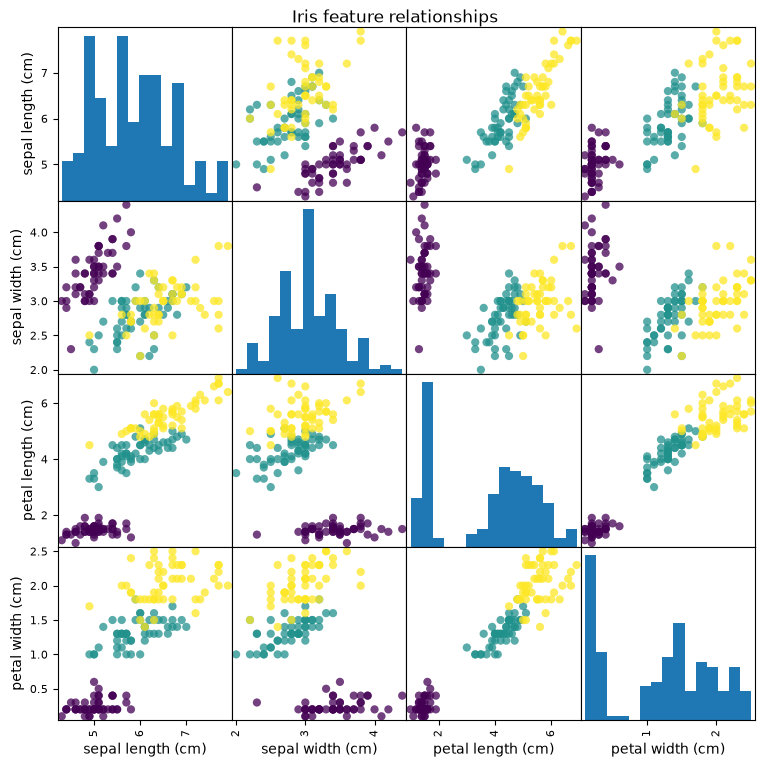

In [3]:
axes = pd.plotting.scatter_matrix(
    iris_df[iris.feature_names], c=iris.target, figsize=(9, 9),
    marker="o", hist_kwds={"bins": 15}, s=35, alpha=0.75
)
plt.suptitle("Iris feature relationships", y=0.9)
plt.show()

Train shape: (112, 4) Test shape: (38, 4)
Predicted species for first test row: setosa
Test accuracy: 0.974


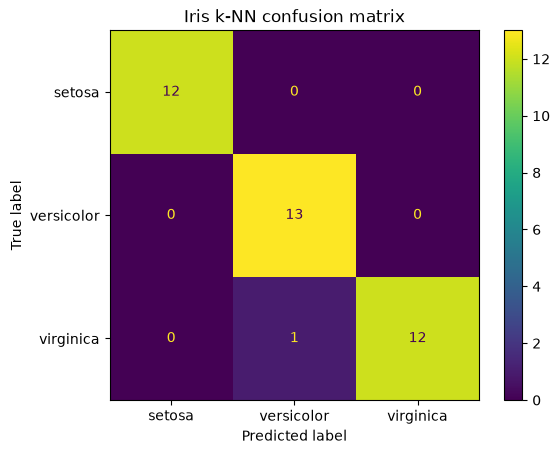

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

X_train, X_test, y_train, y_test = train_test_split(
    iris.data, iris.target, test_size=0.25, stratify=iris.target, random_state=42
)
model = KNeighborsClassifier(n_neighbors=3)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Train shape:", X_train.shape, "Test shape:", X_test.shape)
print("Predicted species for first test row:", iris.target_names[y_pred[0]])
print(f"Test accuracy: {accuracy_score(y_test, y_pred):.3f}")
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=iris.target_names)
plt.title("Iris k-NN confusion matrix")
plt.show()

## Key Takeaways
- Start with the question and the data, not an algorithm.
- Rows are samples, columns are features, and the target is what supervised learning predicts.
- Keep test data isolated until final evaluation.
- Inspect distributions and relationships before modeling.
- A compact scikit-learn workflow is `split -> fit -> predict -> evaluate`.